# ARIMA — Checkpoint (week 4)

Maak per dataset een ARIMA-analyse met grid search naar optimale (p,d,q)-parameters.

## BELANGRIJK: gebruik exact de genoemde variabelennamen
De checks (`checks/test_week04.py`) voeren dit notebook uit en controleren volgende
variabelen. Gebruik exact deze namen, anders falen de checks:

- Oefening 1 (TF_BIRTHS): `series_births`, `births_2022_daily`, `monthly_births`,
  `best_order_births`, `rmse_births`
- Oefening 2 (AQI Duitsland): `aqi_germany`, `aqi_filtered`, `best_order_aqi`, `rmse_aqi`
- Oefening 3 (Electric Production): `series_electric`, `best_order_electric`, `rmse_electric`
- Meerkeuze: `antwoord_adf`, `antwoord_seizoen_births` (waarde "A", "B", "C" of "D")

Conventies die de checks gebruiken: alle grid searches met `p_values = [0, 1, 2, 4]`,
`d_values = [0, 1]`, `q_values = [0, 1]` en een 66/34 train/test-split
(`train_size = int(len(X) * 0.66)`) zoals in de gegeven helperfuncties.


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from math import sqrt
from datetime import datetime
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_pacf
from sklearn.metrics import mean_squared_error

warnings.filterwarnings("ignore")

def evaluate_arima_model(X, arima_order):
    """Walk-forward validatie: RMSE van een ARIMA(order) op reeks X (66/34-split)."""
    X = np.asarray(X, dtype="float32").ravel()
    train_size = int(len(X) * 0.66)
    train, test = X[0:train_size], X[train_size:]
    history = [x for x in train]
    predictions = list()
    for t in range(len(test)):
        model = ARIMA(history, order=arima_order)
        model_fit = model.fit()
        predictions.append(model_fit.forecast()[0])
        history.append(test[t])
    return sqrt(mean_squared_error(test, predictions))

def grid_search_arima(X, p_values, d_values, q_values):
    """Zoekt beste (p,d,q) via walk-forward RMSE. Geeft (best_order, best_rmse)."""
    best_score, best_cfg = float("inf"), None
    for p in p_values:
        for d in d_values:
            for q in q_values:
                try:
                    rmse = evaluate_arima_model(X, (p, d, q))
                except Exception:
                    continue
                if rmse < best_score:
                    best_score, best_cfg = rmse, (p, d, q)
    return best_cfg, best_score

p_values = [0, 1, 2, 4]
d_values = [0, 1]
q_values = [0, 1]


## Oefening 1 — TF_BIRTHS (geboortecijfers België)

1. Laad `./data/TF_BIRTHS.csv` in (scheidingsteken `;`) en hernoem de kolom
   `MS_NUM_BIRTHS` naar `value`. Parse de eerste kolom (`DT_DATE`, formaat
   `%d/%m/%Y`) als index. Sla op in **`series_births`** (DataFrame).
2. Maak **`births_2022_daily`**: enkel de dagcijfers van 2022. Maak een plot en
   bekijk het histogram van de dagcijfers — wat valt op? Hoe komt dat ?
3. Maak **`monthly_births`**: de volledige reeks hersamplet naar maanden (som).
   Welk seizoenspatroon zie je? (beantwoord de meerkeuzevraag verderop)
4. Test met de ADF-test of de maandreeks stationair is.
5. Zoek met grid search de beste ARIMA-parameters voor de maandreeks en sla op in
   **`best_order_births`** (tuple) en de bijhorende walk-forward RMSE in
   **`rmse_births`**.
6. Fit het finale model en plot de residuals.


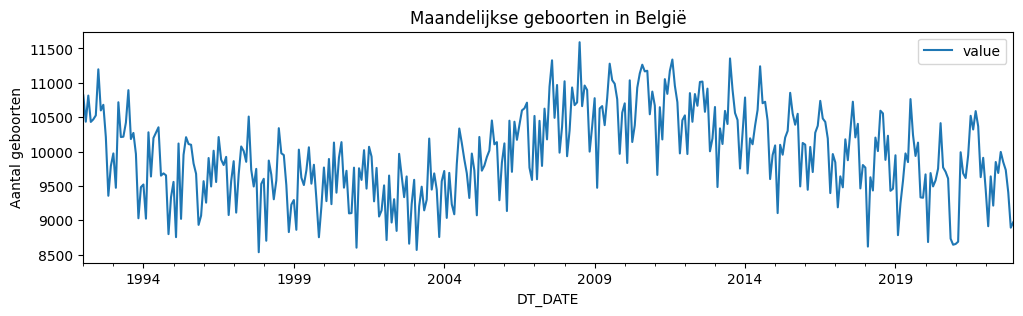

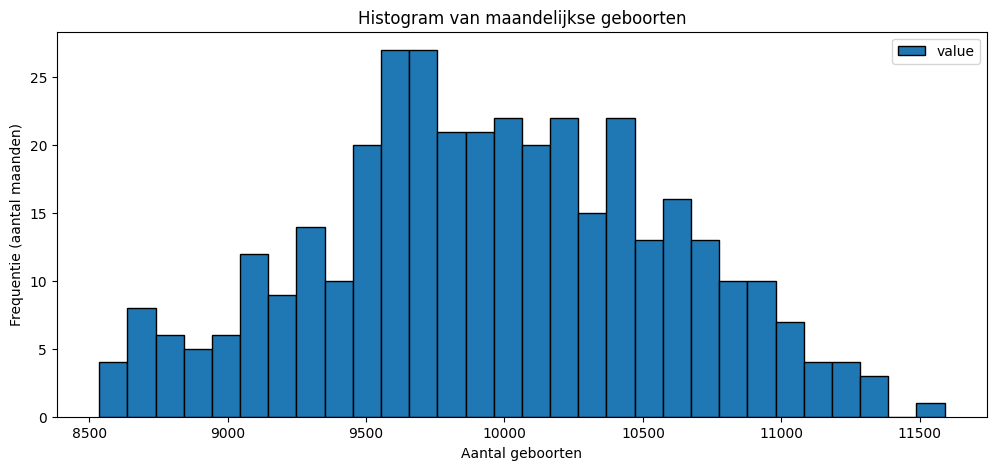

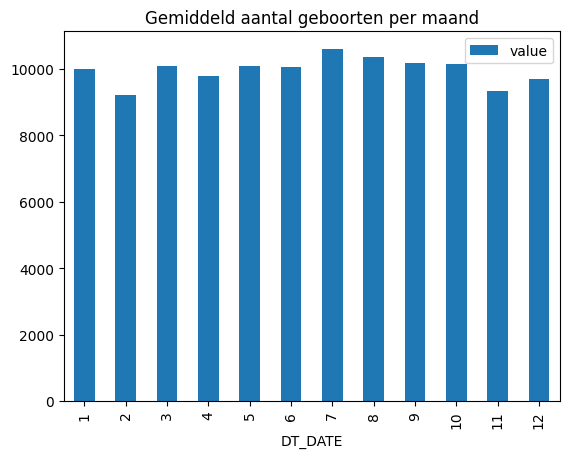

ADF statistiek: -1.219986
p-waarde: 0.664940


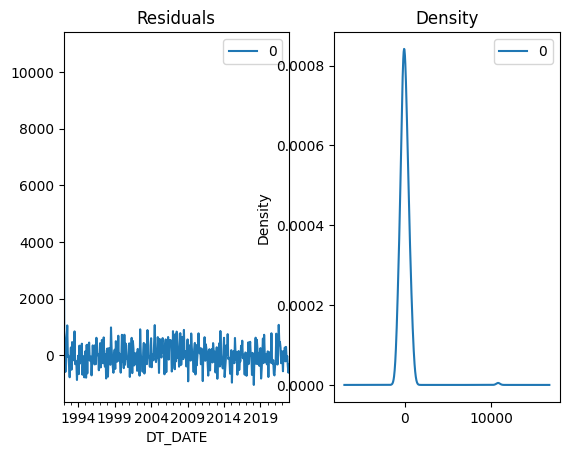

In [ ]:
# TODO: vul hier je oplossing in (zie opdracht hierboven)

# Stap 1
series_births = pd.read_csv("./data/TF_BIRTHS.csv", sep=';', index_col=0, parse_dates=['DT_DATE'], date_format='%d/%m/%Y')
series_births.rename(columns={'MS_NUM_BIRTHS': 'value'}, inplace=True)

# Stap 2
births_2022_daily = series_births.loc['2022']
# births_2022_daily.plot(figsize=(6, 3), title="Dagelijkse geboorten in België (2022)")
# plt.ylabel("Aantal geboorten")
# plt.show()
# births_2022_daily.plot(kind='hist', bins=30, figsize=(6, 3), title="Histogram van dagelijkse geboorten (2022)", edgecolor='black')
# plt.xlabel("Aantal geboorten")
# plt.ylabel("Frequentie (aantal dagen)")
# plt.show()
# Er zijn in het histogram duidelijk twee bulten te zien (=bimodale verdeling). Dit kan te wijten zijn aan het week-weekend regime. Op weekdagen gebeuren er meer geboortes, dan in het weekend. Daarom hebben we eigenlijk een weekgemiddelde en een weekendgemiddelde (dat lager ligt) waarond geboortecijfers zich groeperen.

# Stap 3
monthly_births = series_births[['value']].resample('M').sum()
monthly_births.plot(figsize=(12, 3), title="Maandelijkse geboorten in België")
plt.ylabel("Aantal geboorten")
plt.show()
monthly_births.plot(kind='hist', bins=30, figsize=(12, 5), title="Histogram van maandelijkse geboorten", edgecolor='black')
plt.xlabel("Aantal geboorten")
plt.ylabel("Frequentie (aantal maanden)")
plt.show()
monthly_births.groupby(monthly_births.index.month).mean().plot(kind='bar', title="Gemiddeld aantal geboorten per maand")
plt.show()

# Stap 4
result = adfuller(monthly_births.value.dropna())
print('ADF statistiek: %f' % result[0])
print('p-waarde: %f' % result[1])
# De p-waarde is groter dan 0.05, er is dus differencing nodig.

# Stap 5
best_order_births, rmse_births = grid_search_arima(monthly_births['value'].dropna(), p_values, d_values, q_values)

# Stap 6
model = ARIMA(monthly_births['value'].dropna(), order=best_order_births)
model_fit = model.fit()

residuals = pd.DataFrame(model_fit.resid)
fig, ax = plt.subplots(1,2)
residuals.plot(title="Residuals", ax=ax[0])
residuals.plot(kind='kde', title='Density', ax=ax[1])
plt.show()

## Oefening 2 — AQI: luchtkwaliteit Duitsland

1. Laad `./data/data_date.csv` in (eerste kolom = datum-index).
2. Filter op `Country == 'Germany'` en hou enkel de kolom `AQI Value` (hernoemd naar
   `value`). Sla op in **`aqi_germany`**.
3. Filter de data tussen 21 juli 2022 en 22 september 2022 → **`aqi_filtered`**.
4. Test met de ADF-test of de reeks stationair is (beantwoord daarna de
   meerkeuzevraag `antwoord_adf`).
5. Grid search → **`best_order_aqi`** en **`rmse_aqi`**. Fit het finale model en
   plot de residuals.


ADF statistiek: -4.119410
p-waarde: 0.000899


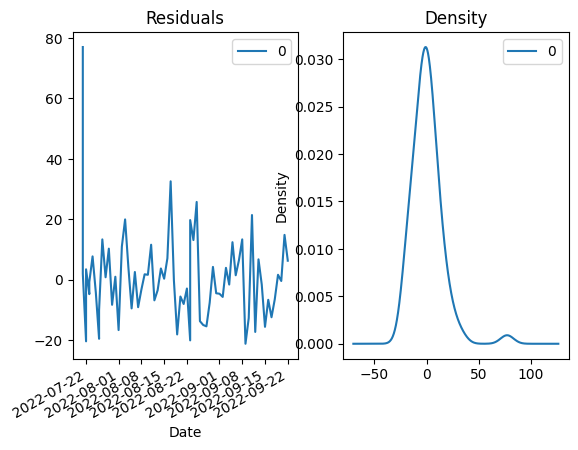

In [ ]:
# TODO: vul hier je oplossing in (zie opdracht hierboven)
# Stap 1
df = pd.read_csv('./data/data_date.csv', sep=',', index_col=0, parse_dates=True, date_format='%Y-%m-%d')

# Stap 2
df.rename(columns={'AQI Value': 'value'}, inplace=True)
aqi_germany = df[df['Country'] == 'Germany'][['value']]

# Stap 3
aqi_germany = aqi_germany.sort_index()
aqi_filtered = aqi_germany.loc['2022-07-21':'2022-09-22']

# Stap 4
result = adfuller(aqi_filtered.value.dropna())
print('ADF statistiek: %f' % result[0])
print('p-waarde: %f' % result[1])
# De p-waarde is kleiner dan 0.05, er is dus geen differencing nodig.

# Stap 5
best_order_aqi, rmse_aqi = grid_search_arima(aqi_filtered['value'].dropna(), p_values, d_values, q_values)

# Stap 6
model = ARIMA(aqi_filtered['value'].dropna(), order=best_order_aqi)
model_fit = model.fit()

residuals = pd.DataFrame(model_fit.resid)
fig, ax = plt.subplots(1,2)
residuals.plot(title="Residuals", ax=ax[0])
residuals.plot(kind='kde', title='Density', ax=ax[1])
plt.show()


## Oefening 3 — Electric Production

1. Laad `./data/Electric_Production.xls` in (het is effectief een CSV; eerste kolom =
   datum-index) en hernoem `Value` naar `value` → **`series_electric`**.
2. Bekijk de reeks: hier is duidelijk een trend én een seizoenspatroon, dus `d = 1`
   is een goede keuze voor de differencing.
3. Grid search → **`best_order_electric`** en **`rmse_electric`**. Fit het finale
   model en plot walk-forward voorspellingen tegen de testset.


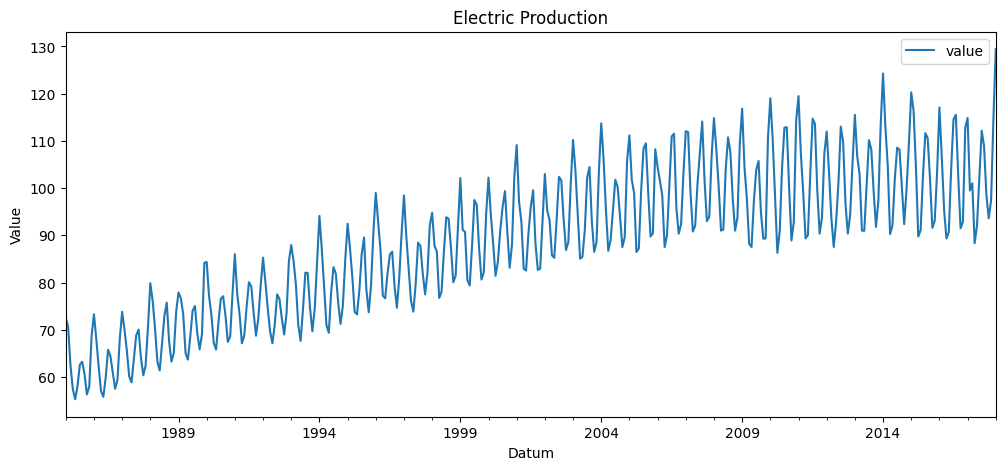

ADF statistiek: -2.256990
p-waarde: 0.186215


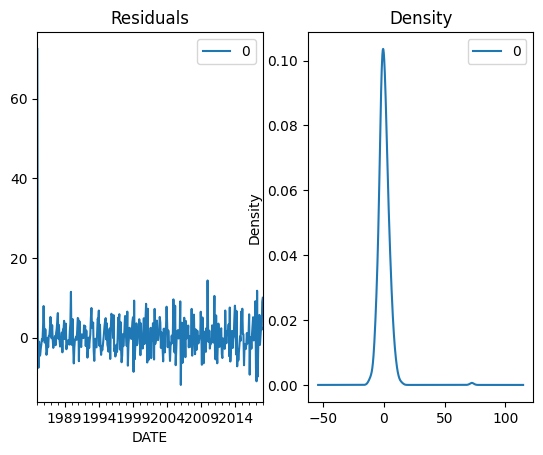

In [6]:
# TODO: vul hier je oplossing in (zie opdracht hierboven)
# Stap 1
series_electric = pd.read_csv('./data/Electric_Production.xls', sep=",", index_col=0, parse_dates=True)
series_electric.rename(columns={'Value': 'value'}, inplace=True)

# Stap 2
series_electric.plot(figsize=(12, 5), title="Electric Production")
plt.ylabel("Value")
plt.xlabel("Datum")
plt.show()
result = adfuller(series_electric.value.dropna())
print('ADF statistiek: %f' % result[0])
print('p-waarde: %f' % result[1])

# Stap 3
best_order_electric, rmse_electric = grid_search_arima(series_electric['value'].dropna(), p_values, d_values, q_values)

# Stap 6
model = ARIMA(series_electric['value'].dropna(), order=best_order_electric)
model_fit = model.fit()

residuals = pd.DataFrame(model_fit.resid)
fig, ax = plt.subplots(1,2)
residuals.plot(title="Residuals", ax=ax[0])
residuals.plot(kind='kde', title='Density', ax=ax[1])
plt.show()


## Meerkeuzevragen

**Vraag 1 (ADF):** de p-waarde van de ADF-test op de gefilterde AQI-reeks van Duitsland
is kleiner dan 0.05. Wat betekent dit?

- A) De reeks is niet-stationair; er is differencing nodig
- B) De reeks is stationair; differencing is niet nodig
- C) De reeks heeft een sterke trend
- D) De ADF-test zegt niets over stationariteit

**Vraag 2 (seizoen geboortes):** welk seizoenspatroon zie je in de maandelijkse
geboortecijfers van België?

- A) Geen enkel seizoenspatroon
- B) Een piek rond juli-september
- C) Enkel een piek in december
- D) Een lineair dalende trend zonder seizoenen


In [7]:
# Vraag 1: vul "A", "B", "C" of "D" in
antwoord_adf = "B"

In [8]:
# Vraag 2: vul "A", "B", "C" of "D" in
antwoord_seizoen_births = "B"